In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

In [2]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing/espectros_derivada_PrimeiraOrdem.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing"
output_path = os.path.join(output_dir, 'espectros_bandas_filtradas.csv')

In [4]:
df = pd.read_csv(input_path)
data = df.values
data

array([[-4.82200995e+00, -4.05676856e+00, -3.29152717e+00, ...,
        -4.67614787e-02, -5.54846978e-02, -6.42079168e-02],
       [-4.83617290e+00, -4.06832454e+00, -3.30047617e+00, ...,
        -3.18260162e-02, -3.70106596e-02, -4.21953031e-02],
       [ 3.16605029e-02,  2.84519155e-02,  2.52433280e-02, ...,
        -6.47932354e-02, -7.01387810e-02, -7.54843265e-02],
       ...,
       [ 4.56078749e-03,  3.92082077e-03,  3.28085405e-03, ...,
         2.19807125e-03,  2.73341149e-03,  3.26875174e-03],
       [-1.25909052e-03, -1.03673202e-03, -8.14373514e-04, ...,
         1.93336790e-03,  2.88156150e-03,  3.82975509e-03],
       [ 1.44409638e-02,  1.24454413e-02,  1.04499188e-02, ...,
        -7.67831970e-04,  3.45523659e-04,  1.45887929e-03]],
      shape=(78808, 256))

In [5]:
variancias = np.var(data, axis=0)
limiar = 0.1 * np.max(variancias)
bandas_ruidosas = np.where(variancias < limiar)[0]
print("Bandas ruidosas detectadas:", bandas_ruidosas)

Bandas ruidosas detectadas: [  4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19  20  21
  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36  37  38  39
  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54  55  56  57
  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72  73  74  75
  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90  91  92  93
  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108 109 110 111
 112 113 114 115 116 117 118 123 124 125 126 127 128 129 130 131 132 133
 134 135 136 137 138 139 140 141 142 143 144 145 146 147 148 149 150 151
 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167 168 169
 170 171 172 173 174 175 176 190 191 192 193 194 195 196 197 198 199 200
 201 202 203 204 205 206 207 208 209 210 211 212 213 214 215 216 217 218
 219 220 221 222 223 224 225 226 227 228 229 248 249 250]


In [8]:
data_filtrada = np.delete(data, bandas_ruidosas, axis=1)
colunas_filtradas = [c for i, c in enumerate(df.columns) if i not in bandas_ruidosas]

In [ ]:
df_filtrado = pd.DataFrame(data_filtrada, columns=colunas_filtradas)
df_filtrado.to_csv(output_path, index=False)

print("Arquivo com bandas filtradas salvo com sucesso em:\n", output_path)

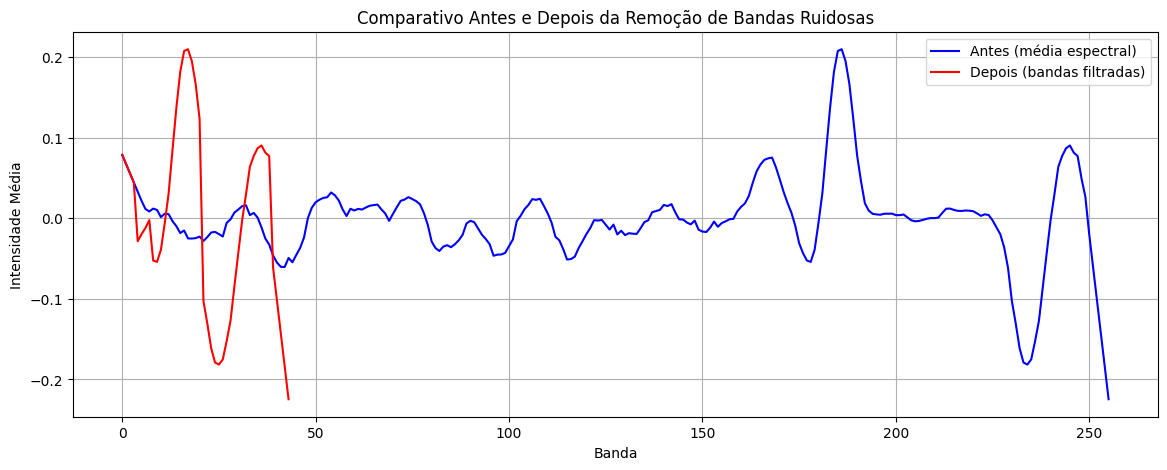

In [10]:
media_antes = np.mean(data, axis=0)
media_depois = np.mean(data_filtrada, axis=0)

plt.figure(figsize=(14,5))
plt.plot(media_antes, label='Antes (média espectral)', color='blue')
plt.plot(np.arange(len(media_depois)), media_depois, label='Depois (bandas filtradas)', color='red')
plt.title("Comparativo Antes e Depois da Remoção de Bandas Ruidosas")
plt.xlabel("Banda")
plt.ylabel("Intensidade Média")
plt.legend()
plt.grid(True)
plt.show()